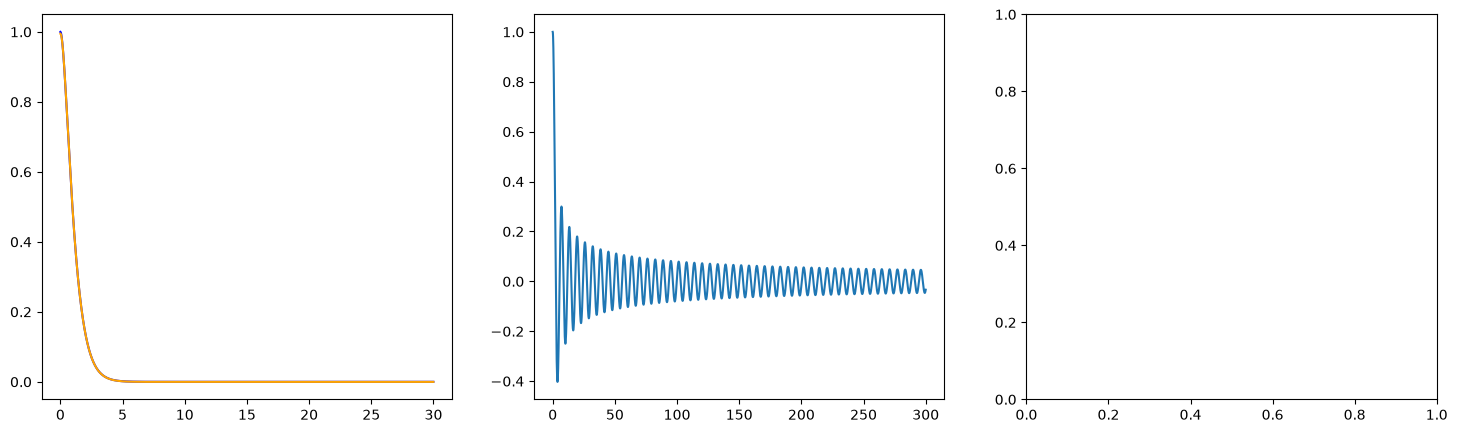

In [11]:
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import jax.random as jr
import jax.scipy.special as jss
import healpy as hp
import astropy as ap
from astropy.coordinates import SkyCoord
from dustmaps.edenhofer2023 import Edenhofer2023Query
import astropy.units as u
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)
logvar = jnp.log(1)
logscale = jnp.log(1)
lognu = jnp.log(1.5)
dx = 0.01
dw = 0.05
num_omegas = 200
num_rs = 3000
omegas = jnp.arange(num_omegas)*dw
rs = jnp.arange(num_rs)*dx
bessel_xs = jnp.arange(num_omegas*num_rs)*dx*dw


def J0(x):
    fineness = 200
    dtheta = jnp.pi / fineness
    theta_range = jnp.arange(fineness) * dtheta
    integrands = jnp.cos(jnp.asarray(x)[..., None] * jnp.sin(theta_range))
    return jnp.sum(integrands, axis=-1) * dtheta / jnp.pi

bessel_values = J0(bessel_xs)

def matern_spectral_density(omega, params, d=2):
    logvar, logscale, lognu = params
    nu = jnp.exp(lognu)
    log_norm = (logvar
                + d * jnp.log(2 * jnp.sqrt(jnp.pi))
                + jss.gammaln(nu + d / 2) - jss.gammaln(nu)
                + d * (logscale - 0.5 * jnp.log(2 * nu)))
    x = jnp.square(omega) * jnp.exp(2 * logscale - jnp.log(2.0) - lognu)
    return jnp.exp(log_norm - (nu + d / 2) * jnp.log1p(x))


def matern_32(r, variance=jnp.exp(logvar), scale=jnp.exp(logscale), jitter=1e-6):
    result = variance * (1 + jnp.sqrt(3)*r/scale)*jnp.exp(-1*jnp.sqrt(3)*r/scale);
    return jnp.where(r > 0, result, result * (1.0 + jitter))

def matern_covariance_by_hankel_2D(r_index, params):
    bessel_input_indices = r_index*jnp.arange(num_omegas)
    integrands = omegas*matern_spectral_density(omegas, params)*bessel_values[bessel_input_indices]*dw
    return jnp.sum(integrands)/(2*jnp.pi)


fig, axes = plt.subplots(1, 3, figsize = (18, 5))
axes[0].plot(rs, matern_32(rs), color = "blue")
hardcoded_cov_array = jax.vmap(matern_covariance_by_hankel_2D, in_axes=(0, None))(
    jnp.arange(num_rs), (logvar, logscale, lognu))
axes[0].plot(rs, hardcoded_cov_array, color="orange")
axes[1].plot(bessel_xs, bessel_values)

Cholesky ok: True


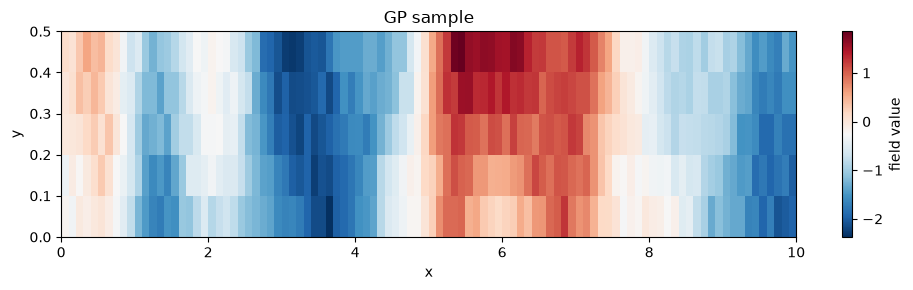

In [12]:
dx_field = 0.1
field_width = 100
field_height = 5


N = field_width*field_height
shape = (field_width, field_height)
gp_grid = jnp.zeros(shape)
flat_gp_grid = jnp.arange(field_width*field_height)
cov_matrix = jnp.zeros((N, N))

ix, iy = jnp.meshgrid(jnp.arange(field_width), jnp.arange(field_height),
                          indexing="ij")
coords = dx_field * jnp.stack([ix.ravel(), iy.ravel()], axis=-1).astype(jnp.float64)  

d2 = jnp.zeros((N, N))
for k in range(2):
    d2 = d2 + (coords[:, k, None] - coords[None, :, k])**2
dist = jnp.sqrt(d2)
del d2

cov_matrix = jnp.interp(dist, rs, hardcoded_cov_array)
del dist

# sample
jitter = 1e-2
L = jnp.linalg.cholesky(cov_matrix + jitter * jnp.eye(N))
print("Cholesky ok:", not jnp.any(jnp.isnan(L)))

key = jr.PRNGKey(0)
sample = (L @ jr.normal(key, (N,))).reshape(shape)

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(
    sample.T,                         # transpose so x runs horizontally
    origin="lower",
    aspect="auto",
    extent=[0, field_width * dx_field, 0, field_height * dx_field],
    cmap="RdBu_r",
)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"GP sample")
fig.colorbar(im, ax=ax, label="field value")
plt.tight_layout()
plt.show()

In [13]:
import numpy as np
import healpy as hp
import jax.numpy as jnp
from astropy.io import fits

from hmc_dust import DATA, GAIA

# Sightline strip definition
lon = 0.0            # target Galactic longitude (degrees)
lat_center = 0.0     # latitude the strip is centred on (degrees)
n_sightlines = 21    # number of consecutive HEALPix rings to include

with fits.open(DATA / "mean_and_std_healpix.fits") as hdul:
    hdul.info()
    mean_hdr = hdul["MEAN"].header
    print(mean_hdr["ORDERING"])
    print(hdul["STD."].header["ORDERING"])

    nside = mean_hdr.get("NSIDE", 256)
    nest = mean_hdr["ORDERING"].strip().upper() == "NESTED"

    # Ring geometry: rings are numbered 1 (north pole) to 4*nside - 1 (south pole)
    n_rings = 4 * nside - 1
    startpix, ringpix, costheta, _, _ = hp.ringinfo(nside, np.arange(1, n_rings + 1))
    ring_lats = 90.0 - np.degrees(np.arccos(costheta))   # decreasing with ring number

    # Choose n_sightlines consecutive rings centred on the ring nearest lat_center
    center = np.argmin(np.abs(ring_lats - lat_center))
    start = center - (n_sightlines - 1) // 2
    stop = start + n_sightlines
    if start < 0 or stop > n_rings:
        raise ValueError("Requested strip runs past a pole; reduce n_sightlines or move lat_center.")
    rings = np.arange(start, stop)[::-1]   # reversed so latitude increases along the axis

    # In each ring, pick the pixel whose centre is closest in longitude to `lon`
    pix_ring = np.empty(n_sightlines, dtype=np.int64)
    for k, r in enumerate(rings):
        candidates = startpix[r] + np.arange(ringpix[r])
        cand_lon, _ = hp.pix2ang(nside, candidates, nest=False, lonlat=True)
        dlon = (cand_lon - lon + 180.0) % 360.0 - 180.0   # wrap to [-180, 180)
        pix_ring[k] = candidates[np.argmin(np.abs(dlon))]

    # Actual pixel-centre coordinates of each sightline
    pix_lons, latitudes = hp.pix2ang(nside, pix_ring, nest=False, lonlat=True)

    # Convert to the file's ordering before indexing
    pix = hp.ring2nest(nside, pix_ring) if nest else pix_ring

    # Shape: (n_radial, n_sightlines)
    mean_along_strip = jnp.asarray(hdul["MEAN"].data[:, pix].astype(np.float32))
    std_along_strip  = jnp.asarray(hdul["STD."].data[:, pix].astype(np.float32))

    radial_centers    = jnp.asarray(hdul["RADIAL PIXEL CENTERS"].data.field(0),    dtype=jnp.float32)
    radial_boundaries = jnp.asarray(hdul["RADIAL PIXEL BOUNDARIES"].data.field(0), dtype=jnp.float32)
    distance_gaps = np.diff(radial_boundaries)

print(f"Latitude span: {latitudes[0]:.4f} to {latitudes[-1]:.4f} deg")
print(f"Pixel-centre longitudes: {np.unique(np.round(pix_lons, 4))}")
print(mean_along_strip.shape)   # (n_radial, n_sightlines)

Filename: /home/dtfrake/hmc-dust/Data_And_Samplers/mean_and_std_healpix.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       9   ()      
  1  MEAN          1 ImageHDU        19   (786432, 516)   float32   
  2  STD.          1 ImageHDU        19   (786432, 516)   float32   
  3  RADIAL PIXEL CENTERS    1 BinTableHDU     20   516R x 1C   [E]   
  4  RADIAL PIXEL BOUNDARIES    1 BinTableHDU     20   517R x 1C   [E]   
  5  MEAN OF INTEGRATED INNER 68.8 PC    1 ImageHDU        16   (786432,)   float32   
  6  STD. OF INTEGRATED INNER 68.8 PC    1 ImageHDU        16   (786432,)   float32   
NEST
NEST
Latitude span: -1.4922 to 1.4922 deg
Pixel-centre longitudes: [0.     0.1758]
(516, 21)


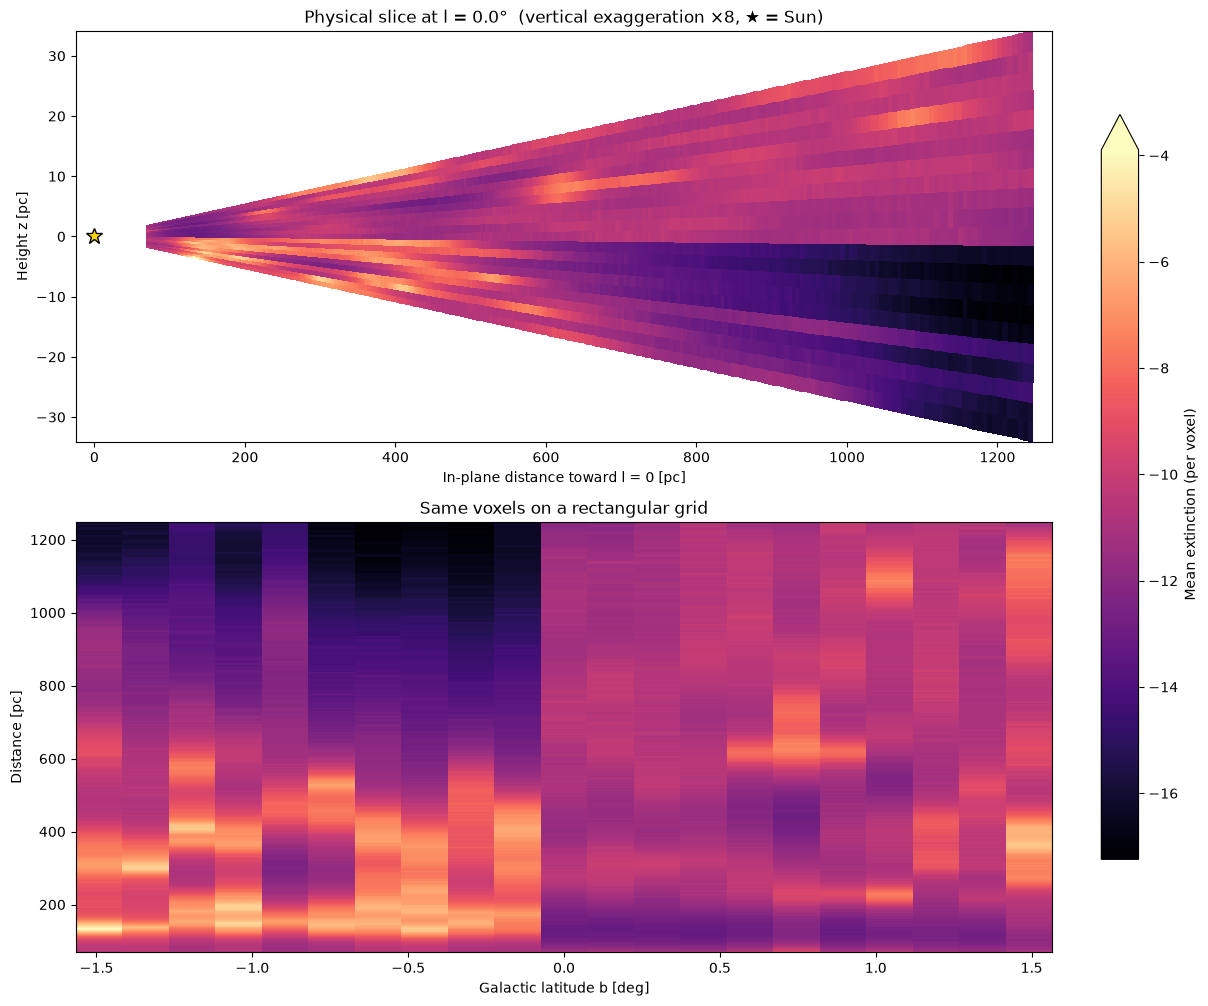

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Display settings ----
vertical_exaggeration = 8.0    # stretch factor for the height axis (1.0 = true scale)
saturation_percentile = 98.0   # colours saturate above this percentile of the data
cmap = "magma"

mean_np = np.asarray(mean_along_strip)    # (n_radial, n_sightlines)
r_edges = np.asarray(radial_boundaries)   # (n_radial + 1,)
lat = np.asarray(latitudes)
assert mean_np.shape == (len(r_edges) - 1, len(lat)), "shape mismatch"

# Latitude edges: midpoints between neighbouring rings, extrapolated at the ends
mid = 0.5 * (lat[:-1] + lat[1:])
lat_edges = np.concatenate([[2 * lat[0] - mid[0]], mid, [2 * lat[-1] - mid[-1]]])


# Voxel corners in the l = 0 plane: x = in-plane distance, z = height above the plane
B, R = np.meshgrid(np.radians(lat_edges), r_edges)   # (n_radial + 1, n_sightlines + 1)
X = R * np.cos(B)
Z = R * np.sin(B)

mesh_kw = dict(cmap=cmap, shading="flat",
               edgecolors="none", linewidth=0, antialiased=False, rasterized=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), constrained_layout=True)

# ---- Top: physical wedge, with vertical exaggeration ----
mesh = ax1.pcolormesh(X, Z, jnp.log(mean_np), **mesh_kw)
ax1.plot(0, 0, marker="*", color="gold", markersize=12, markeredgecolor="k", zorder=5)
ax1.set_aspect(vertical_exaggeration)
ax1.set_xlim(-0.02 * r_edges[-1], 1.02 * r_edges[-1])
ax1.set_xlabel("In-plane distance toward l = 0 [pc]")
ax1.set_ylabel("Height z [pc]")
ax1.set_title(f"Physical slice at l = {lon:.1f}°  (vertical exaggeration ×{vertical_exaggeration:g}, ★ = Sun)")

# ---- Bottom: latitude vs distance ----
ax2.pcolormesh(lat_edges, r_edges, jnp.log(mean_np), **mesh_kw)
ax2.set_xlabel("Galactic latitude b [deg]")
ax2.set_ylabel("Distance [pc]")
ax2.set_title("Same voxels on a rectangular grid")

fig.colorbar(mesh, ax=[ax1, ax2], label="Mean extinction (per voxel)",
             extend="max", shrink=0.8)
plt.show()

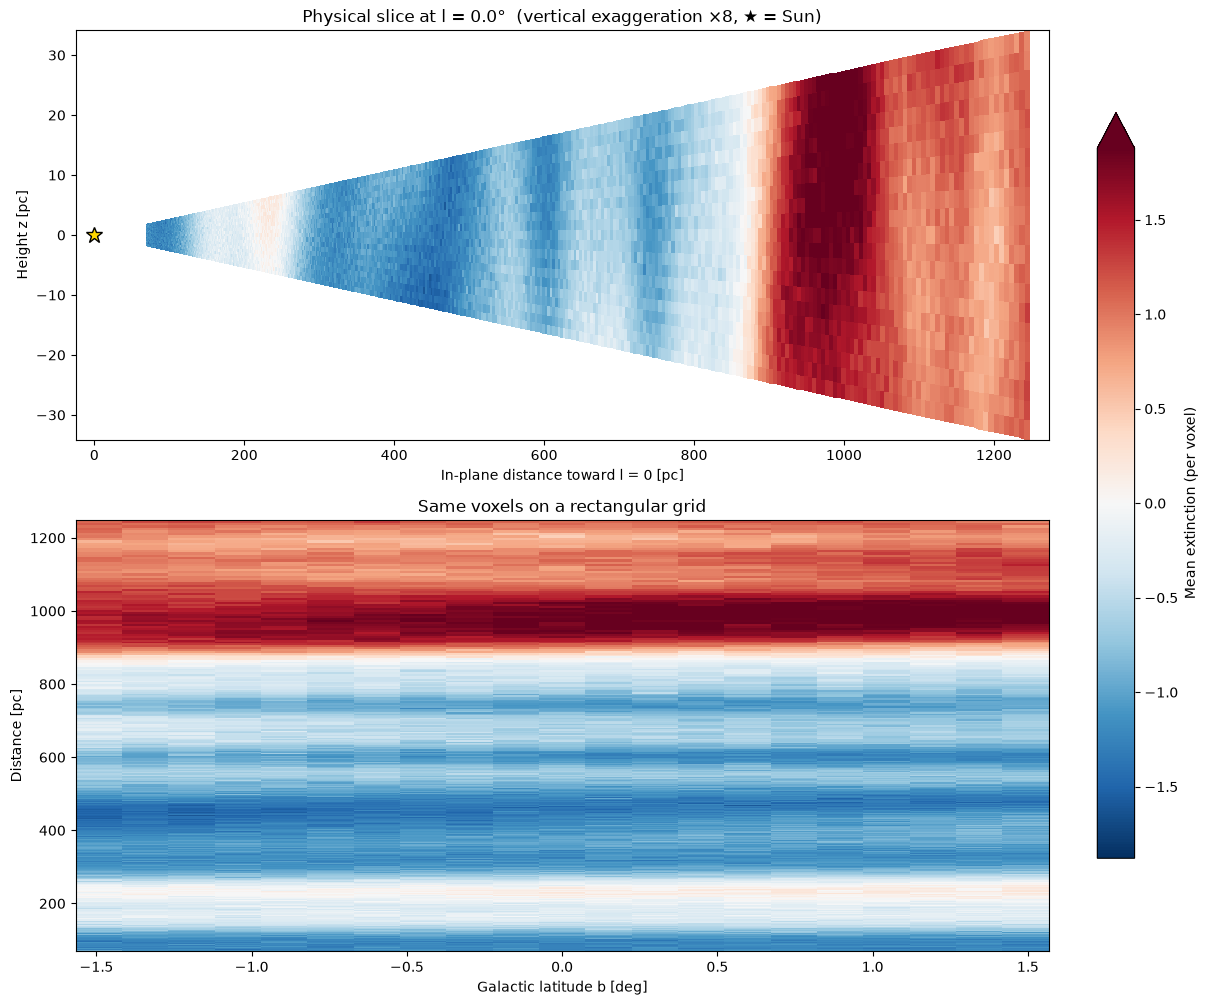

In [18]:
n_radial, n_sight = radial_centers.size, latitudes.size
N = n_radial * n_sight
scale_in_pc = 100

# Unit vector toward each sightline's pixel centre (heliocentric Galactic frame:
# x toward the Galactic centre, y toward l = 90°, z toward the north Galactic pole)
unit = jnp.asarray(np.stack(hp.pix2vec(nside, pix, nest=nest), axis=-1),
                   dtype=jnp.float32)                       # (n_sight, 3)

# Cell-centre positions in pc: distance times direction
positions = radial_centers[:, None, None] * unit[None, :, :]  # (n_radial, n_sight, 3)
flat_pos = positions.reshape(N, 3)                           # (N, 3)

def pairwise_distances(p):
    # Sum over coordinates one at a time: avoids an (N, N, 3) temporary array
    # and keeps small separations accurate in float32
    d2 = sum((p[:, k, None] - p[None, :, k]) ** 2 for k in range(3))
    return jnp.sqrt(d2)/scale_in_pc

dist = pairwise_distances(flat_pos)                          # (N, N), in pc
dense_cov_matrix = jnp.interp(dist, rs, hardcoded_cov_array)
jitter = 5e-3
L = jnp.linalg.cholesky(dense_cov_matrix + jitter*jnp.eye(N))
key = jr.PRNGKey(1)
sample = (L @ jr.normal(key, (N,))).reshape(n_radial, n_sightlines)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), constrained_layout=True)

s = np.asarray(sample)
lim = np.percentile(np.abs(s), 99)
sample_kw = {**mesh_kw, "cmap": "RdBu_r", "vmin": -lim, "vmax": lim}

# ---- Top: physical wedge, with vertical exaggeration ----
mesh = ax1.pcolormesh(X, Z, sample, **sample_kw)
ax1.plot(0, 0, marker="*", color="gold", markersize=12, markeredgecolor="k", zorder=5)
ax1.set_aspect(vertical_exaggeration)
ax1.set_xlim(-0.02 * r_edges[-1], 1.02 * r_edges[-1])
ax1.set_xlabel("In-plane distance toward l = 0 [pc]")
ax1.set_ylabel("Height z [pc]")
ax1.set_title(f"Physical slice at l = {lon:.1f}°  (vertical exaggeration ×{vertical_exaggeration:g}, ★ = Sun)")

# ---- Bottom: latitude vs distance ----
ax2.pcolormesh(lat_edges, r_edges, sample, **sample_kw)
ax2.set_xlabel("Galactic latitude b [deg]")
ax2.set_ylabel("Distance [pc]")
ax2.set_title("Same voxels on a rectangular grid")

fig.colorbar(mesh, ax=[ax1, ax2], label="Mean extinction (per voxel)",
             extend="max", shrink=0.8)
plt.show()
